# Charge analysis

The figures compare SO3LR ionic charges and molecular dipoles with APPLE&P and electronic-structure references at identical geometries.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle

start = Path.cwd().resolve()
repo = next(path for path in (start, *start.parents)
            if (path / '07_charges/data/pes_scan.csv').is_file())
chapter = repo / '07_charges'
figures = chapter / 'figures'
figures.mkdir(exist_ok=True)

convergence = pd.read_csv(chapter / 'data/charge_convergence.csv', comment='#')
neutral = pd.read_csv(chapter / 'data/neutral_control.csv', comment='#')
thumbnails = pd.read_csv(chapter / 'data/neutral_control_geometries.csv', comment='#')
pes = pd.read_csv(chapter / 'data/pes_scan.csv', comment='#')

# Paul Tol bright, the same colour and marker per force field as chapters 04-06.
colours = {'APPLE&P': '#0077BB', 'SO3LR': '#EE7733', 'CL&P': '#009988', 'CL&P-scaled': '#CC3311'}
markers = {'APPLE&P': 'o', 'SO3LR': 's', 'CL&P': '^', 'CL&P-scaled': 'D'}
# DFT takes the slot chapter 05 gives experiment: black, white-filled marker, dashed.
dft_colour = 'black'
# Two figures plot only SO3LR, so there colour encodes the ion or the species class.
cation_colour, anion_colour = colours['APPLE&P'], colours['CL&P-scaled']

# 18 pt, matching the published figures. Chapters 04-06 inline 14 pt; see the chapter
# README for why this one differs.
plt.rcParams.update({'font.size': 18, 'font.family': 'sans-serif', 'axes.labelsize': 18,
                     'xtick.labelsize': 18, 'ytick.labelsize': 18, 'axes.linewidth': 1.5,
                     'lines.linewidth': 2.5, 'axes.grid': False})

KE_EV_A = 14.399645351950548      # e^2 / (4 pi eps0) in eV Angstrom
EV_TO_KJ_MOL = 96.48533212
LR_CUTOFF_A = 12.0                # SO3LR force-shifts its electrostatics to zero here
RECEPTIVE_FIELD_A = 13.5          # 3 message passes x 4.5 A cutoff
PLATEAU_MIN_SEPARATION_A = 16.0   # 16 and 18 A pair energies agree within 0.001 kJ/mol


def box(ax):
    """Full boxed axes with 1.5 pt black spines, the convention across all chapters."""
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
        spine.set_color('black')
    ax.tick_params(width=1.5, length=7)


def inline_legend(ax, entries, x_frac, y_frac, dy, fontsize=18, ha='center'):
    """Coloured bold text instead of a legend box."""
    for index, (label, colour) in enumerate(entries):
        ax.text(x_frac, y_frac - index * dy, label, transform=ax.transAxes,
                fontsize=fontsize, fontweight='bold', va='center', ha=ha, color=colour)


print(f'{len(convergence)} convergence rows, {len(neutral)} species, {len(pes)} scan points')

/home/akryachkova/ams2025.106/bin/python3.8/lib/python3.8/site-packages/mpl_toolkits/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__('pkg_resources').declare_namespace(__name__)


/home/akryachkova/.conda/envs/so3lr312/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


31 convergence rows, 8 species, 20 scan points


## 1. Charge versus cluster radius

For six central ion pairs in one 300 K bulk configuration, the net charge is evaluated in charge-neutral clusters of increasing radius. The shaded region is one standard error over these six spatial samples. The dashed line marks the 13.5 Å receptive field and the dotted line the periodic-bulk mean.

Wrote /gpfs/home5/akryachkova/emimntf2-paper-repro/07_charges/figures/charge_convergence.png
isolated pair |q| = 0.3608 / 0.3608
converged     |q| = 0.2623 / 0.2361
periodic bulk |q| = 0.2515


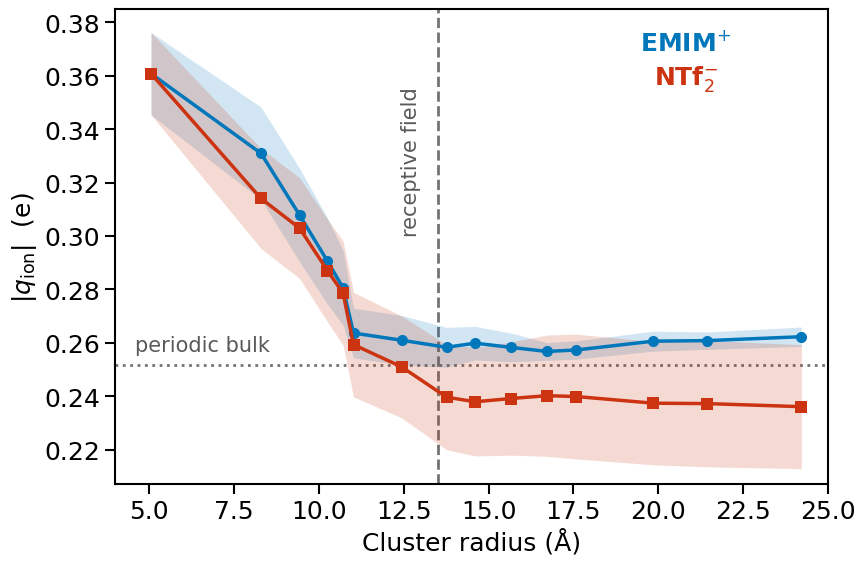

In [2]:
cluster = convergence[convergence.series == 'cluster']
bulk = float(convergence.loc[convergence.series == 'periodic_bulk', 'abs_q_e'].iloc[0])

fig, ax = plt.subplots(figsize=(9.0, 6.0))
ax.axvline(RECEPTIVE_FIELD_A, color='0.45', ls='--', lw=2.0, zorder=1)
ax.axhline(bulk, color='0.45', ls=':', lw=2.0, zorder=1)
ax.text(RECEPTIVE_FIELD_A - 0.5, 0.300, 'receptive field', rotation=90,
        va='bottom', ha='right', fontsize=15, color='0.35')
ax.text(4.6, bulk + 0.004, 'periodic bulk', ha='left', va='bottom',
        fontsize=15, color='0.35')

for ion, colour, marker in (('EMIM+', cation_colour, 'o'), ('NTf2-', anion_colour, 's')):
    series = cluster[cluster.ion == ion].sort_values('radius_A')
    ax.fill_between(series.radius_A, series.abs_q_e - series.abs_q_sem_e,
                    series.abs_q_e + series.abs_q_sem_e,
                    color=colour, alpha=0.18, lw=0, zorder=2)
    ax.plot(series.radius_A, series.abs_q_e, color=colour, lw=2.5, marker=marker,
            ms=8, mew=0.0, zorder=3)

ax.set_xlabel('Cluster radius (Å)')
ax.set_ylabel(r'$|q_\mathrm{ion}|$  (e)')
ax.set_xlim(4.0, 25.0)
ax.set_ylim(0.207, 0.385)
inline_legend(ax, [(r'EMIM$^{+}$', cation_colour), (r'NTf$_2^{-}$', anion_colour)],
              x_frac=0.80, y_frac=0.93, dy=0.075)
box(ax)
fig.tight_layout()

output = figures / 'charge_convergence.png'
fig.savefig(output, dpi=300, bbox_inches='tight', facecolor='white')
print(f'Wrote {output}')

emim = cluster[cluster.ion == 'EMIM+'].sort_values('radius_A')
ntf2 = cluster[cluster.ion == 'NTf2-'].sort_values('radius_A')
print(f'isolated pair |q| = {emim.abs_q_e.iloc[0]:.4f} / {ntf2.abs_q_e.iloc[0]:.4f}')
print(f'converged     |q| = {emim.abs_q_e.iloc[-1]:.4f} / {ntf2.abs_q_e.iloc[-1]:.4f}')
print(f'periodic bulk |q| = {bulk:.4f}')

## 2. Neutral-analogue dipole control

SO3LR and DFT dipoles are compared at identical geometries. Six of seven neutral molecules agree within 7%; HNTf₂ has a ratio of 1.34. The ion-pair value is based on 50 geometries.

/home/akryachkova/tmp/ipykernel_486274/525229405.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=0.4)


Wrote /gpfs/home5/akryachkova/emimntf2-paper-repro/07_charges/figures/neutral_control.png
neutrals: 6/7 within 7%, range 1.006-1.340
ion pair: 0.477


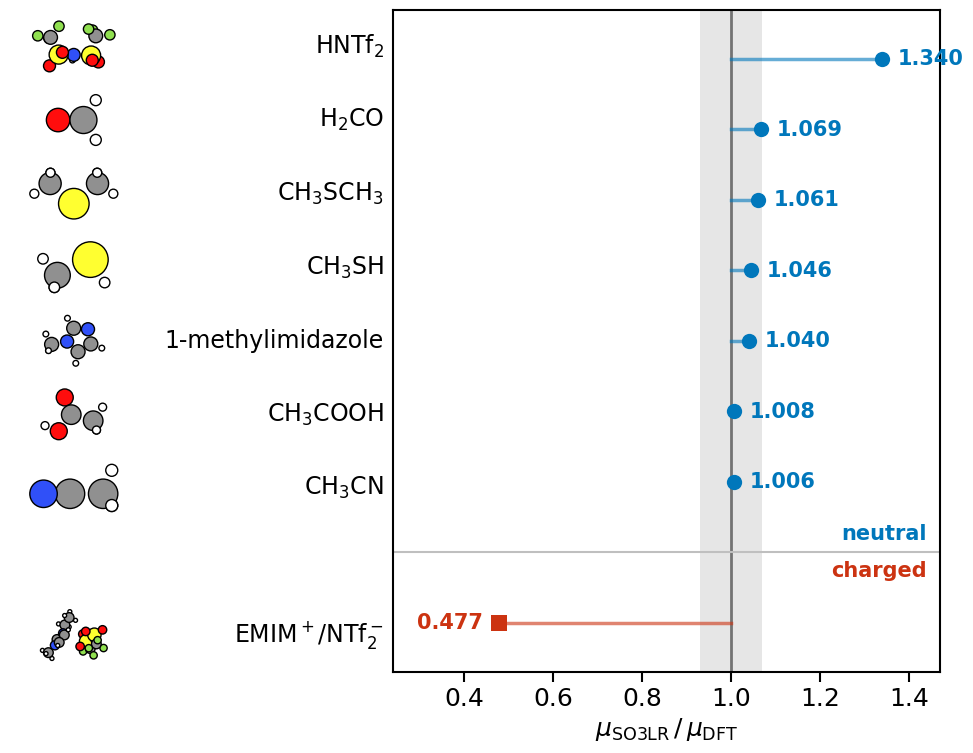

In [3]:
# ASE is not a dependency of this repository, so the thumbnails are drawn directly:
# depth-sorted circles at the covalent radius, coloured by element. These are ASE's own
# covalent radii and jmol colours, so the rendering matches the published figure.
COVALENT_RADIUS_A = {'H': 0.31, 'C': 0.76, 'N': 0.71, 'O': 0.66, 'F': 0.57, 'S': 1.05}
ELEMENT_COLOUR = {'H': (1.000, 1.000, 1.000), 'C': (0.565, 0.565, 0.565),
                  'N': (0.188, 0.314, 0.973), 'O': (1.000, 0.051, 0.051),
                  'F': (0.565, 0.878, 0.314), 'S': (1.000, 1.000, 0.188)}
TOLERANCE = 0.07     # the "within 7 %" band quoted in the text


def principal_projection(frame):
    """Project a molecule onto its own principal plane -- the most legible view."""
    positions = frame[['x_A', 'y_A', 'z_A']].to_numpy()
    centred = positions - positions.mean(axis=0)
    _, _, basis = np.linalg.svd(centred, full_matrices=False)
    return centred @ basis.T


def draw_molecule(ax, frame, scale):
    """Space-filling circles, far atoms first so near ones overlap them."""
    projected = principal_projection(frame)
    radii = np.array([COVALENT_RADIUS_A[e] for e in frame.element]) * scale
    for index in np.argsort(projected[:, 2]):
        x, y, _ = projected[index]
        ax.add_patch(Circle((x, y), radii[index],
                            facecolor=ELEMENT_COLOUR[frame.element.iloc[index]],
                            edgecolor='black', lw=1.0, zorder=2))
    # Fit each axis to the atoms including their radii, then pad by 1.45 about that
    # axis's own centre so neighbouring rows do not touch. Equal aspect squares the box
    # afterwards. Doing it per axis rather than on a single square span is what keeps the
    # molecules the same apparent size as in the published figure.
    for get_limit, set_limit, column in ((ax.get_xlim, ax.set_xlim, 0),
                                         (ax.get_ylim, ax.set_ylim, 1)):
        low = (projected[:, column] - radii).min()
        high = (projected[:, column] + radii).max()
        middle, half = 0.5 * (low + high), 0.5 * (high - low) * 1.45
        set_limit(middle - half, middle + half)
    ax.set_aspect('equal')
    ax.set_axis_off()


# Neutrals ascending in ratio, with the ion pair first and one blank slot between them.
ordered = pd.concat([neutral[neutral.charged], neutral[~neutral.charged].sort_values('ratio')])
rows = list(ordered.itertuples())
slots = [0] + list(range(2, 2 + len(rows) - 1))
n_slots = slots[-1] + 1

fig = plt.figure(figsize=(12.0, 8.6))
grid = fig.add_gridspec(n_slots, 3, width_ratios=[0.14, 0.26, 0.60],
                        wspace=0.03, hspace=0.0)
ax = fig.add_subplot(grid[:, 2])
ax.axvspan(1 - TOLERANCE, 1 + TOLERANCE, color='0.90', lw=0, zorder=0)
ax.axvline(1.0, color='0.45', lw=2.0, zorder=1)

for row, y in zip(rows, slots):
    colour = anion_colour if row.charged else cation_colour
    ax.plot([1.0, row.ratio], [y, y], color=colour, lw=2.5, alpha=0.6, zorder=2)
    ax.plot([row.ratio], [y], marker='s' if row.charged else 'o', ms=11,
            color=colour, mew=0, zorder=3)
    dx, ha = (-0.035, 'right') if row.ratio < 1.0 else (0.035, 'left')
    ax.text(row.ratio + dx, y, f'{row.ratio:.3f}', va='center', ha=ha,
            fontsize=15, fontweight='bold', color=colour)

# The divider sits in the blank slot: the charged row is below it, the neutrals above.
ax.axhline(1.0, color='0.75', lw=1.5, zorder=1)
ax.text(1.44, 1.12, 'neutral', fontsize=15, color=cation_colour, fontweight='bold',
        va='bottom', ha='right')
ax.text(1.44, 0.88, 'charged', fontsize=15, color=anion_colour, fontweight='bold',
        va='top', ha='right')

ax.set_yticks([])
ax.set_ylim(-0.7, n_slots - 0.3)
ax.set_xlim(0.24, 1.47)
ax.set_xlabel(r'$\mu_{\mathrm{SO3LR}}\,/\,\mu_{\mathrm{DFT}}$')
box(ax)
ax.tick_params(axis='y', length=0)

for row, y in zip(rows, slots):
    grid_row = n_slots - 1 - y
    structure = fig.add_subplot(grid[grid_row, 0])
    structure.set_anchor('C')
    draw_molecule(structure, thumbnails[thumbnails.species == row.species],
                  scale=0.95 if row.charged else 0.85)
    caption = fig.add_subplot(grid[grid_row, 1])
    caption.text(1.0, 0.5, row.label, ha='right', va='center', fontsize=17,
                 transform=caption.transAxes)
    caption.set_axis_off()

fig.tight_layout(pad=0.4)

output = figures / 'neutral_control.png'
fig.savefig(output, dpi=300, bbox_inches='tight', facecolor='white')
print(f'Wrote {output}')

within = neutral[~neutral.charged]
print(f'neutrals: {(within.ratio - 1).abs().le(TOLERANCE).sum()}/{len(within)} within '
      f'{TOLERANCE:.0%}, range {within.ratio.min():.3f}-{within.ratio.max():.3f}')
print(f'ion pair: {neutral.loc[neutral.charged, "ratio"].iloc[0]:.3f}')

## 3. Gas-phase dissociation scan

The frozen EMIM⁺--NTf₂⁻ separation scan compares interaction energies and net cation charges. Each conventional interaction-energy curve uses fragments evaluated with the same method; the displayed SO3LR curve uses its intact-pair plateau as the reference.

/home/akryachkova/tmp/ipykernel_486274/1464056870.py:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Wrote /gpfs/home5/akryachkova/emimntf2-paper-repro/07_charges/figures/pes_scan.png
well depths: DFT -275.8 at 4.5 A, APPLE&P -279.2 at 4.5 A, SO3LR/formal fragments -181.4 at 4.5 A
SO3LR pair-energy plateau at >= 16 A: -125.1 kJ/mol on the formal-fragment scale (spread 0.0008)
SO3LR well relative to the pair plateau: -56.3 kJ/mol at 4.5 A; 0.204 x DFT
APPLE&P at 18 A: -75.7 vs -ke/r = -77.2 kJ/mol


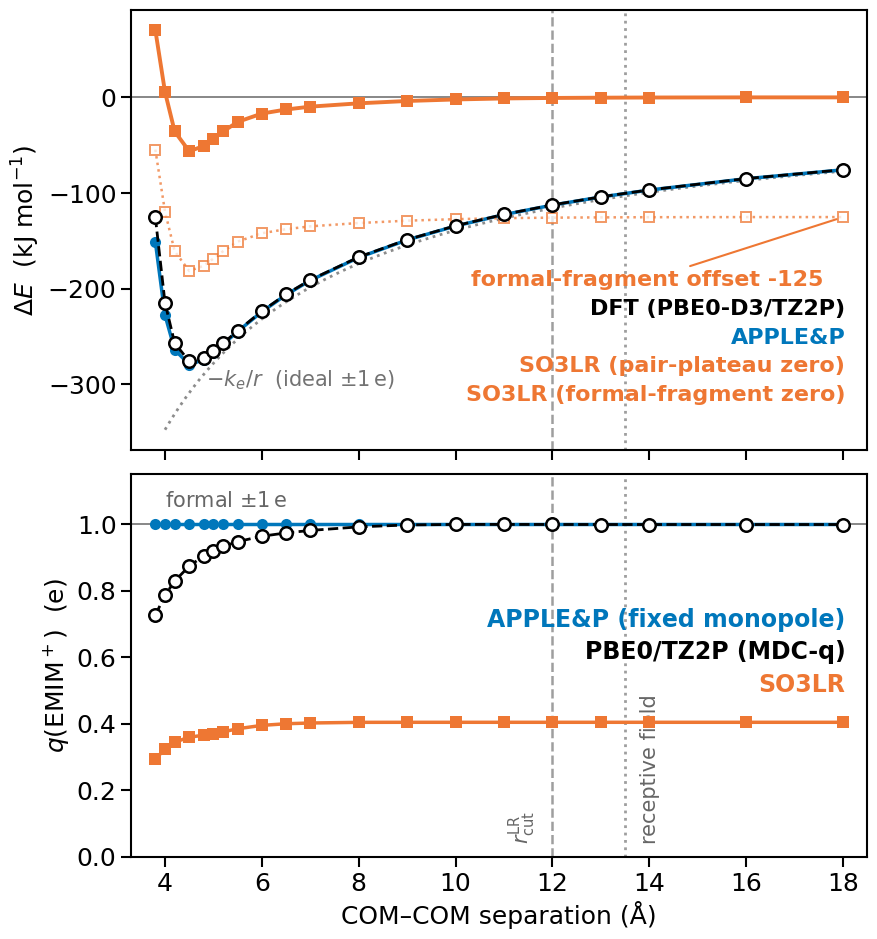

In [4]:
separation = pes.separation_A.to_numpy()
far = separation >= PLATEAU_MIN_SEPARATION_A
plateau = float(pes.dE_so3lr_kJ_mol[far].mean())
spread = float(pes.dE_so3lr_kJ_mol[far].max() - pes.dE_so3lr_kJ_mol[far].min())
pair_plateau = pes.dE_so3lr_pair_plateau_kJ_mol.to_numpy()

fig, (upper, lower) = plt.subplots(2, 1, figsize=(9.5, 11.0), sharex=True,
                                   gridspec_kw={'height_ratios': [1.15, 1.0],
                                                'hspace': 0.06})
for ax in (upper, lower):
    ax.axvline(LR_CUTOFF_A, color='0.62', ls='--', lw=1.8, zorder=1)
    ax.axvline(RECEPTIVE_FIELD_A, color='0.62', ls=':', lw=2.0, zorder=1)
    box(ax)

# Dotted grey, so the ideal-Coulomb guide cannot be confused with DFT's dashed black.
guide = np.linspace(max(4.0, separation.min()), separation.max(), 200)
upper.plot(guide, -KE_EV_A / guide * EV_TO_KJ_MOL, color='0.55', ls=':', lw=2.0, zorder=2)
upper.plot(separation, pes.dE_pbe0_kJ_mol, color=dft_colour, lw=2.0, ls='--', marker='o',
           ms=9, mfc='white', mew=1.8, zorder=5)
upper.plot(separation, pes.dE_appleP_kJ_mol, color=colours['APPLE&P'], lw=2.5,
           marker=markers['APPLE&P'], ms=8, mew=0, zorder=3)
upper.plot(separation, pes.dE_so3lr_kJ_mol, color=colours['SO3LR'], lw=1.8, ls=':',
           marker=markers['SO3LR'], ms=7, mfc='white', mew=1.4, alpha=0.75, zorder=3)
upper.plot(separation, pair_plateau, color=colours['SO3LR'], lw=2.8,
           marker=markers['SO3LR'], ms=8, mew=0, zorder=4)
upper.axhline(0.0, color='0.45', lw=1.2, zorder=1)
upper.set_ylabel(r'$\Delta E$  (kJ mol$^{-1}$)')
inline_legend(upper, [('DFT (PBE0-D3/TZ2P)', dft_colour), ('APPLE&P', colours['APPLE&P']),
                      ('SO3LR (pair-plateau zero)', colours['SO3LR']),
                      ('SO3LR (formal-fragment zero)', colours['SO3LR'])],
              x_frac=0.97, y_frac=0.32, dy=0.065, ha='right', fontsize=16)
# The guide is labelled on itself, at short r -- the only place it is well separated from
# DFT. Beyond ~6 A the two nearly coincide, which is the point of the figure.
label_at = separation.min() + 0.9
upper.text(label_at + 0.15, -KE_EV_A / label_at * EV_TO_KJ_MOL,
           r'$-k_e/r$  (ideal $\pm1\,$e)', fontsize=15, color='0.45',
           ha='left', va='center')
upper.annotate(f'formal-fragment offset {plateau:+.0f}', xy=(separation[-1], plateau),
               xytext=(separation[-1] - 0.4, plateau - 55), fontsize=16,
               color=colours['SO3LR'], fontweight='bold', ha='right', va='top',
               arrowprops=dict(arrowstyle='-', lw=1.5, color=colours['SO3LR'],
                               shrinkA=2, shrinkB=5))

lower.axhline(1.0, color='0.45', lw=1.2, zorder=1)
lower.text(4.0, 1.04, r'formal $\pm1\,$e', fontsize=15, color='0.4', ha='left', va='bottom')
lower.plot(separation, pes.q_pbe0_mdcq_e, color=dft_colour, lw=2.0, ls='--', marker='o',
           ms=9, mfc='white', mew=1.8, zorder=5)
lower.plot(separation, pes.q_appleP_e, color=colours['APPLE&P'], lw=2.5,
           marker=markers['APPLE&P'], ms=8, mew=0, zorder=3)
lower.plot(separation, pes.q_so3lr_e, color=colours['SO3LR'], lw=2.5,
           marker=markers['SO3LR'], ms=8, mew=0, zorder=4)
lower.set_ylabel(r'$q(\mathrm{EMIM}^+)$  (e)')
lower.set_xlabel('COM–COM separation (Å)')
lower.set_ylim(0.0, 1.15)
inline_legend(lower, [('APPLE&P (fixed monopole)', colours['APPLE&P']),
                      ('PBE0/TZ2P (MDC-q)', dft_colour), ('SO3LR', colours['SO3LR'])],
              x_frac=0.97, y_frac=0.62, dy=0.085, ha='right', fontsize=17)
lower.text(LR_CUTOFF_A - 0.3, 0.04, r'$r_\mathrm{cut}^\mathrm{LR}$', rotation=90,
           fontsize=15, color='0.4', ha='right', va='bottom')
lower.text(RECEPTIVE_FIELD_A + 0.3, 0.04, 'receptive field', rotation=90,
           fontsize=15, color='0.4', ha='left', va='bottom')
upper.set_xlim(separation.min() - 0.5, separation.max() + 0.5)
fig.tight_layout()

output = figures / 'pes_scan.png'
fig.savefig(output, dpi=300, bbox_inches='tight', facecolor='white')
print(f'Wrote {output}')

deepest = pes.loc[pes.dE_pbe0_kJ_mol.idxmin()]
apple = pes.loc[pes.dE_appleP_kJ_mol.idxmin()]
so3lr_fragment = pes.loc[pes.dE_so3lr_kJ_mol.idxmin()]
so3lr_plateau = pes.loc[pes.dE_so3lr_pair_plateau_kJ_mol.idxmin()]
print(f'well depths: DFT {deepest.dE_pbe0_kJ_mol:.1f} at {deepest.separation_A:.1f} A, '
      f'APPLE&P {apple.dE_appleP_kJ_mol:.1f} at {apple.separation_A:.1f} A, '
      f'SO3LR/formal fragments {so3lr_fragment.dE_so3lr_kJ_mol:.1f} at '
      f'{so3lr_fragment.separation_A:.1f} A')
print(f'SO3LR pair-energy plateau at >= {PLATEAU_MIN_SEPARATION_A:.0f} A: '
      f'{plateau:+.1f} kJ/mol on the formal-fragment scale (spread {spread:.4f})')
print(f'SO3LR well relative to the pair plateau: '
      f'{so3lr_plateau.dE_so3lr_pair_plateau_kJ_mol:.1f} kJ/mol at '
      f'{so3lr_plateau.separation_A:.1f} A; '
      f'{so3lr_plateau.dE_so3lr_pair_plateau_kJ_mol / deepest.dE_pbe0_kJ_mol:.3f} x DFT')
print(f'APPLE&P at {separation.max():.0f} A: {pes.dE_appleP_kJ_mol.iloc[-1]:.1f} vs '
      f'-ke/r = {-KE_EV_A / separation.max() * EV_TO_KJ_MOL:.1f} kJ/mol')